<a href="https://colab.research.google.com/github/benameur21/Brain-Tumor-Segmentation-UNet-TL/blob/main/Brain_tumor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/benameur21/Brain-Tumor-Segmentation-UNet-TL.git

Cloning into 'Brain-Tumor-Segmentation-UNet-TL'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 24 (delta 5), reused 3 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 1.23 MiB | 3.99 MiB/s, done.
Resolving deltas: 100% (5/5), done.


In [ ]:
%cd Brain-Tumor-Segmentation-UNet-TL.git
!git status

[Errno 2] No such file or directory: 'Brain-Tumor-Segmentation-UNet-TL.git'
/content
fatal: not a git repository (or any of the parent directories): .git


# Part A

**A0.Environment Setup**

Install Required Libraries

In [ ]:
!pip install -q segmentation-models-pytorch==0.3.4
!pip install -q albumentations
!pip install -q opencv-python matplotlib pandas scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Import Libraries

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Set Random Seed

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


Detect Computing Device

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU: Tesla T4


Q01 : The chosen hardware is the GPU (using CUDA) specifically an NVIDIA Tesla T4 it enhances the speed of simultaneous calculations leading to a decrease in training duration when set against the CPU

**A1.LGG MRI Dataset Exploration**

1.Dataset Inventory

*Define Dataset Path and List Files*

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Path to dataset files: /kaggle/input/lgg-mri-segmentation


In [ ]:
import os
import glob

DATASET_DIR = "/kaggle/input/lgg-mri-segmentation"

all_files = glob.glob(
    os.path.join(DATASET_DIR, "**", "*.tif"),
    recursive=True
)

print("Dataset directory:", DATASET_DIR)
print("Total TIFF files:", len(all_files))
print("First 5 files:", all_files[:5])

Dataset directory: /kaggle/input/lgg-mri-segmentation
Total TIFF files: 15716
First 5 files: ['/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_45.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_56_mask.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_57.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_33.tif', '/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_7010_19860307/TCGA_DU_7010_19860307_27.tif']


*Separate Images and Masks*

In [ ]:
mask_paths = [
    path for path in all_files
    if path.endswith("_mask.tif")
]

mri_paths = [
    path for path in all_files
    if not path.endswith("_mask.tif")
]

print("MRI images:", len(mri_paths))
print("Segmentation masks:", len(mask_paths))

MRI images: 7858
Segmentation masks: 7858


*Match Images and Masks*

In [ ]:
from pathlib import Path

mask_dict = {
    Path(path).stem.replace("_mask", ""): path
    for path in mask_paths
}

image_mask_pairs = []

for image_path in mri_paths:
    image_name = Path(image_path).stem

    if image_name in mask_dict:
        image_mask_pairs.append(
            (image_path, mask_dict[image_name])
        )

print("Matched image-mask pairs:", len(image_mask_pairs))

Matched image-mask pairs: 7858


*Count Patients*

In [ ]:
patient_ids = {
    "_".join(Path(image_path).stem.split("_")[:3])
    for image_path, mask_path in image_mask_pairs
}

print("Number of patients:", len(patient_ids))
print("First 10 patient IDs:", sorted(patient_ids)[:10])

Number of patients: 110
First 10 patient IDs: ['TCGA_CS_4941', 'TCGA_CS_4942', 'TCGA_CS_4943', 'TCGA_CS_4944', 'TCGA_CS_5393', 'TCGA_CS_5395', 'TCGA_CS_5396', 'TCGA_CS_5397', 'TCGA_CS_6186', 'TCGA_CS_6188']


2.Visualize MRI Images and Masks

*Display Sample Images*

In [ ]:
import cv2
import matplotlib.pyplot as plt

def display_samples(pairs, n=3):
    fig, axes = plt.subplots(n, 2, figsize=(10, 4 * n))

    for i, (image_path, mask_path) in enumerate(pairs[:n]):
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        axes[i, 0].imshow(image)
        axes[i, 0].set_title("MRI Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Segmentation Mask")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

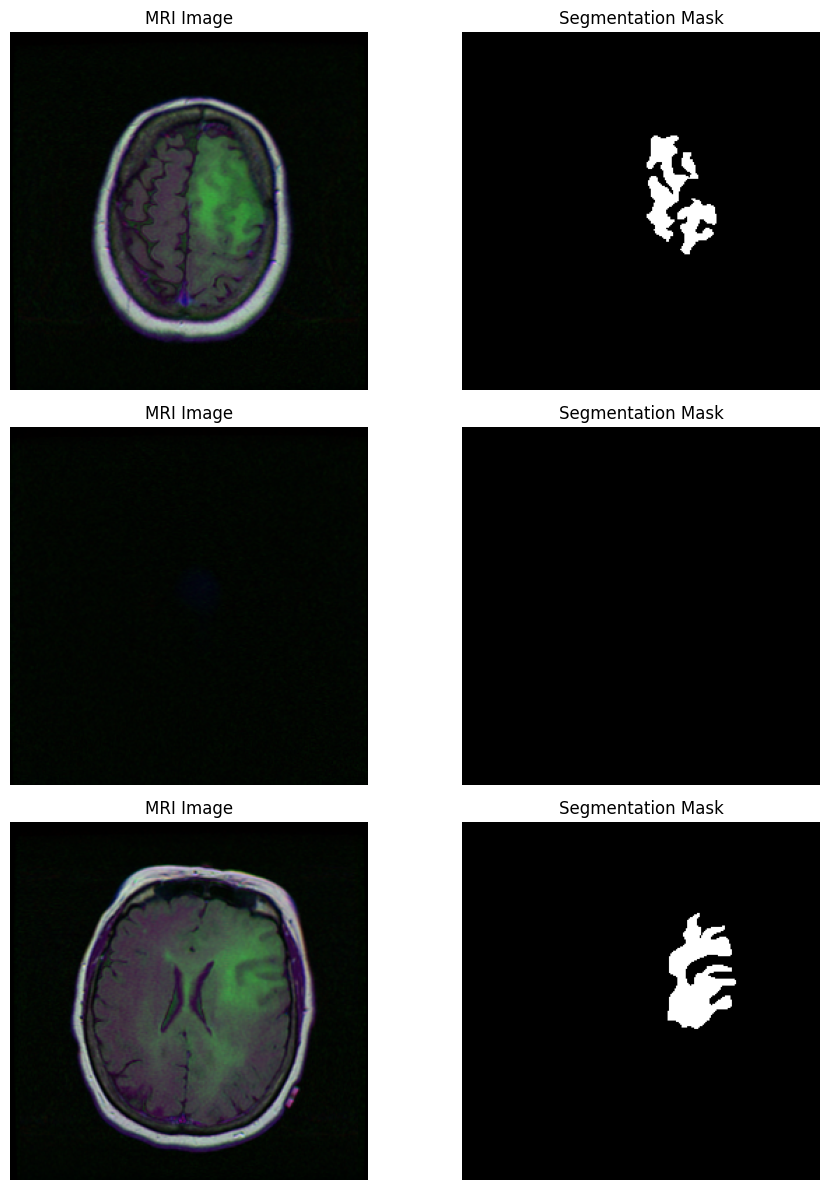

In [ ]:
display_samples(image_mask_pairs, n=3)

*Display Samples With and Without Anomalies*

Samples with anomalies: 2746
Samples without anomalies: 5112

Samples with anomalies:


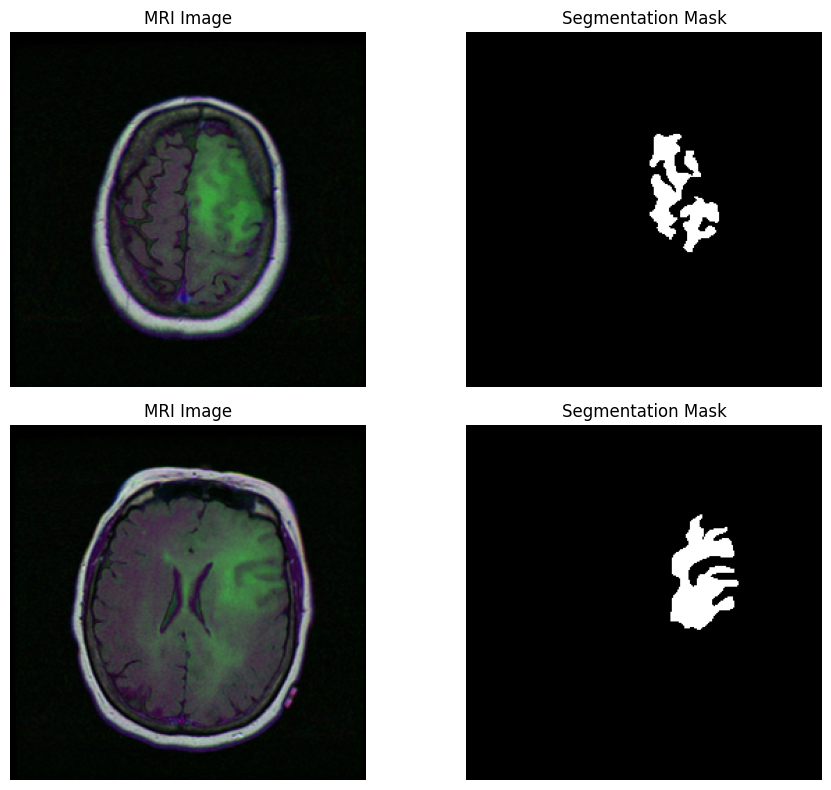


Samples without anomalies:


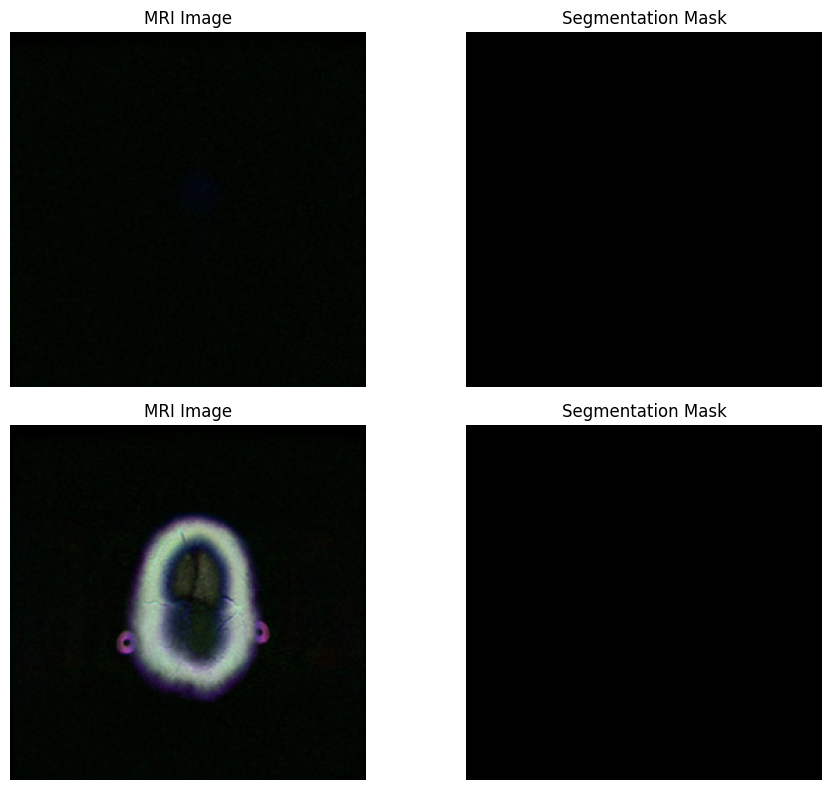

In [ ]:
positive_samples = []
negative_samples = []

for image_path, mask_path in image_mask_pairs:
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if np.any(mask > 0):
        positive_samples.append((image_path, mask_path))
    else:
        negative_samples.append((image_path, mask_path))

print("Samples with anomalies:", len(positive_samples))
print("Samples without anomalies:", len(negative_samples))

print("\nSamples with anomalies:")
display_samples(positive_samples, n=2)

print("\nSamples without anomalies:")
display_samples(negative_samples, n=2)

3.Analyze Mask Values and Empty Masks

*Inspect Mask Pixel Values*

In [ ]:
sample_mask = cv2.imread(
    image_mask_pairs[0][1],
    cv2.IMREAD_GRAYSCALE
)

unique_values = np.unique(sample_mask)

print("Unique mask values:", unique_values)
print("Mask shape:", sample_mask.shape)

Unique mask values: [  0 255]
Mask shape: (256, 256)


*Calculate Empty Mask Statistics*

In [ ]:
total_masks = len(image_mask_pairs)
empty_masks = len(negative_samples)
non_empty_masks = len(positive_samples)

empty_percentage = (empty_masks / total_masks) * 100

print("Total masks:", total_masks)
print("Empty masks:", empty_masks)
print("Non-empty masks:", non_empty_masks)
print(f"Empty mask percentage: {empty_percentage:.2f}%")

Total masks: 7858
Empty masks: 5112
Non-empty masks: 2746
Empty mask percentage: 65.05%


Q02:The dataset includes 7,858 pairs of MRI images and masks linked to 110 individuals.These masks serve as segmentation labels rather than being colored images and they comprise two distinct values: 0 indicating the background and 255 denoting the highlighted tumor area

Q03:A mask that is entirely black signifies that there is no marked tumor area in the related MRI slice, as seen in the second output shown by 'display_samples(image_mask_pairs, n=3)' where both the MRI image and the segmentation mask are nearly completely dark except for some details plus this step is essential to keep these instances during both training and evaluation stages as they assist the model in identifying slices that lack labeled tumors which ultimately helps decrease false-positive outcomes
In this dataset 5,112 masks are empty representing 65.05% of the total


**A2.Data Preparation and Data Leakage Prevention**

1.Patient-Level Data Splitting

*Prepare Patient IDs*

In [ ]:
import random
import numpy as np
from sklearn.model_selection import train_test_split

patient_ids = sorted(list(patient_ids))

print("Total patients:", len(patient_ids))

Total patients: 110


*Split Patients*

In [ ]:
RANDOM_SEED = 42

train_patients, temp_patients = train_test_split(
    patient_ids,
    test_size=0.30,
    random_state=RANDOM_SEED
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=RANDOM_SEED
)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

Training patients: 77
Validation patients: 16
Test patients: 17


2.Select a Fixed Subset

*Organize the dataset by patient*

In [ ]:
from pathlib import Path

def get_patient_id(image_path):
    return "_".join(Path(image_path).stem.split("_")[:3])

train_pairs = []
val_pairs = []
test_pairs = []

for image_path, mask_path in image_mask_pairs:
    patient_id = get_patient_id(image_path)

    if patient_id in train_patients:
        train_pairs.append((image_path, mask_path))

    elif patient_id in val_patients:
        val_pairs.append((image_path, mask_path))

    elif patient_id in test_patients:
        test_pairs.append((image_path, mask_path))

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))
print("Total pairs:", len(train_pairs) + len(val_pairs) + len(test_pairs))

Training pairs: 5500
Validation pairs: 1236
Test pairs: 1122
Total pairs: 7858


*Define the Subset Sizes*

In [ ]:
TRAIN_SIZE = 1000
VAL_SIZE = 200
TEST_SIZE = 200

print("Training subset size:", TRAIN_SIZE)
print("Validation subset size:", VAL_SIZE)
print("Test subset size:", TEST_SIZE)

Training subset size: 1000
Validation subset size: 200
Test subset size: 200


*Select Fixed Subsets*

In [ ]:
random.seed(RANDOM_SEED)

train_subset = random.sample(
    train_pairs,
    min(TRAIN_SIZE, len(train_pairs))
)

val_subset = random.sample(
    val_pairs,
    min(VAL_SIZE, len(val_pairs))
)

test_subset = random.sample(
    test_pairs,
    min(TEST_SIZE, len(test_pairs))
)

print("Training subset:", len(train_subset))
print("Validation subset:", len(val_subset))
print("Test subset:", len(test_subset))

Training subset: 1000
Validation subset: 200
Test subset: 200


*Verify the Selected Subsets*

In [ ]:
total_selected = (
    len(train_subset) +
    len(val_subset) +
    len(test_subset)
)

assert len(train_subset) == min(TRAIN_SIZE, len(train_pairs))
assert len(val_subset) == min(VAL_SIZE, len(val_pairs))
assert len(test_subset) == min(TEST_SIZE, len(test_pairs))

print("Total selected pairs:", total_selected)
print("Subset selection verified successfully.")

Total selected pairs: 1400
Subset selection verified successfully.


*Verify Patient Separation*

In [ ]:
train_subset_patients = {
    get_patient_id(image_path)
    for image_path, mask_path in train_subset
}

val_subset_patients = {
    get_patient_id(image_path)
    for image_path, mask_path in val_subset
}

test_subset_patients = {
    get_patient_id(image_path)
    for image_path, mask_path in test_subset
}

assert train_subset_patients.isdisjoint(val_subset_patients)
assert train_subset_patients.isdisjoint(test_subset_patients)
assert val_subset_patients.isdisjoint(test_subset_patients)

print("No patient overlap between selected subsets")

No patient overlap between selected subsets


3.Image and Mask Resizing

*Define the Target Image Size*

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

IMAGE_SIZE = (224, 224)

print("Target image size:", IMAGE_SIZE)

Target image size: (224, 224)


*Define the Resizing Function*

In [ ]:
def resize_image_mask(image_path, mask_path, size=IMAGE_SIZE):

    image = Image.open(image_path).convert("L")

    mask = Image.open(mask_path).convert("L")

    image = image.resize(
        size,
        resample=Image.Resampling.BILINEAR
    )

    mask = mask.resize(
        size,
        resample=Image.Resampling.NEAREST
    )

    return np.array(image), np.array(mask)

*Resize and Display a Sample*

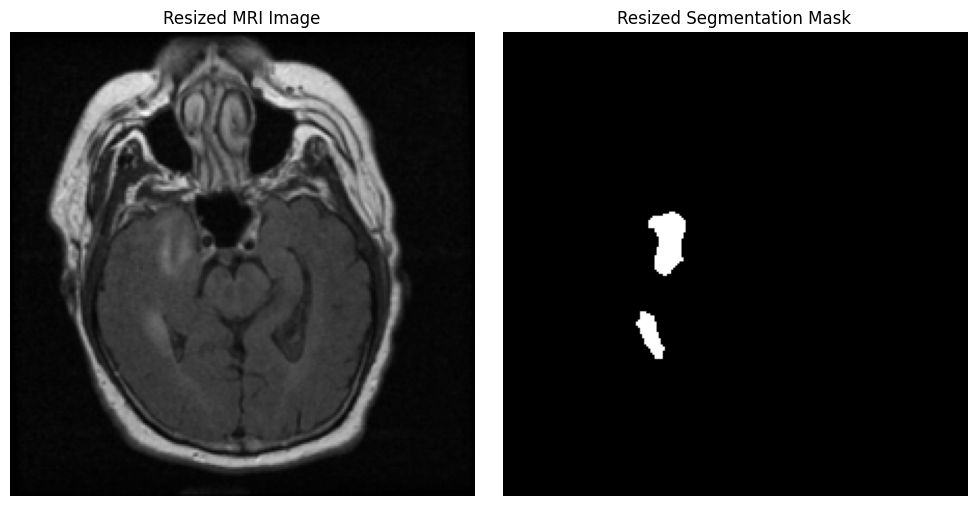

In [ ]:
sample_image_path, sample_mask_path = train_subset[0]

resized_image, resized_mask = resize_image_mask(
    sample_image_path,
    sample_mask_path
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(resized_image, cmap="gray")
axes[0].set_title("Resized MRI Image")
axes[0].axis("off")

axes[1].imshow(resized_mask, cmap="gray")
axes[1].set_title("Resized Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

*Image and Mask Dimensions*

In [ ]:
print("MRI image shape:", resized_image.shape)
print("Segmentation mask shape:", resized_mask.shape)

print("Unique mask values:", np.unique(resized_mask))

MRI image shape: (224, 224)
Segmentation mask shape: (224, 224)
Unique mask values: [  0 255]


4.Create Dataset and DataLoaders

*Define the MRI Segmentation Dataset*

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class MRISegmentationDataset(Dataset):

    def __init__(self, image_mask_pairs):
        self.image_mask_pairs = image_mask_pairs

    def __len__(self):
        return len(self.image_mask_pairs)

    def __getitem__(self, index):

        image_path, mask_path = self.image_mask_pairs[index]

        image, mask = resize_image_mask(
            image_path,
            mask_path
        )

        image = image.astype(np.float32) / 255.0

        mask = (mask > 0).astype(np.float32)

        image = np.stack([image, image, image], axis=0)

        mask = np.expand_dims(mask, axis=0)

        image = torch.tensor(image, dtype=torch.float32)
        mask = torch.tensor(mask, dtype=torch.float32)

        return image, mask

*Create Dataset Objects*

In [ ]:
train_dataset = MRISegmentationDataset(train_subset)
val_dataset = MRISegmentationDataset(val_subset)
test_dataset = MRISegmentationDataset(test_subset)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Training dataset: 1000
Validation dataset: 200
Test dataset: 200


*Create DataLoaders*

In [ ]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")
print("Batch size:", BATCH_SIZE)

DataLoaders created successfully.
Batch size: 16


*Verify DataLoaders*

In [ ]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Image range:", images.min().item(), images.max().item())
print("Unique mask values:", torch.unique(masks))

Images shape: torch.Size([16, 3, 224, 224])
Masks shape: torch.Size([16, 1, 224, 224])
Image dtype: torch.float32
Mask dtype: torch.float32
Image range: 0.0 0.7921568751335144
Unique mask values: tensor([0., 1.])


*Display a Sample*

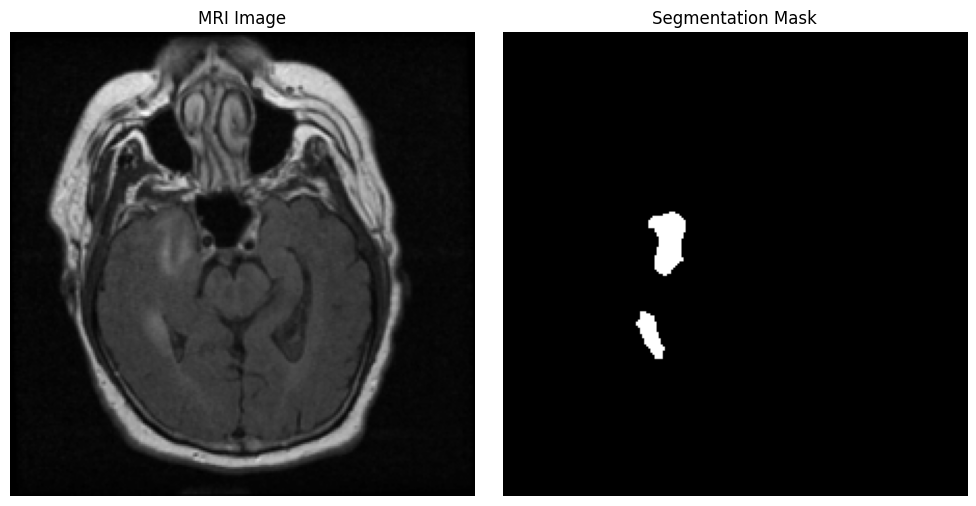

In [ ]:
image, mask = train_dataset[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(image[0].numpy(), cmap="gray")
axes[0].set_title("MRI Image")
axes[0].axis("off")

axes[1].imshow(mask[0].numpy(), cmap="gray")
axes[1].set_title("Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Q04:Splitting the data according to patients helps avoid data leakage. This method guarantees that segments from the identical patient are not present in both the training and testing groups which facilitates a more trustworthy assessment on patients who have not been seen before

Q05:NEAREST maintains the initial mask labels(0 and 255) without generating any in-between values and BILINEAR is ideal for MRI images since it yields more fluid outcomes through the interpolation of pixel brightness

**A3.Create the U-Net Model**

1.Define the U-Net Model

In [ ]:
import torch
import segmentation_models_pytorch as smp


model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
)

model = model.to(DEVICE)

print("U-Net model created successfully.")

Downloading: "https://download.pytorch.org/models/resnet34-333f7ec4.pth" to /root/.cache/torch/hub/checkpoints/resnet34-333f7ec4.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 191MB/s]


U-Net model created successfully.


2.Test the Model

In [ ]:
sample_input = torch.randn(2, 3, 224, 224).to(DEVICE)

model.eval()

with torch.no_grad():
    output = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 1, 224, 224])


3.Freeze the Encoder

*Freeze ResNet34 Parameters*

In [ ]:
for param in model.encoder.parameters():
    param.requires_grad_(False)

print("ResNet34 encoder frozen successfully  ")

ResNet34 encoder frozen successfully  


*Check Trainable Parameters*

In [ ]:
print("Trainable components:")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

total_params = sum(
    param.numel()
    for param in model.parameters()
)

print("\nTrainable parameters:", trainable_params)
print("Total parameters:", total_params)

Trainable components:
decoder.blocks.0.conv1.0.weight
decoder.blocks.0.conv1.1.weight
decoder.blocks.0.conv1.1.bias
decoder.blocks.0.conv2.0.weight
decoder.blocks.0.conv2.1.weight
decoder.blocks.0.conv2.1.bias
decoder.blocks.1.conv1.0.weight
decoder.blocks.1.conv1.1.weight
decoder.blocks.1.conv1.1.bias
decoder.blocks.1.conv2.0.weight
decoder.blocks.1.conv2.1.weight
decoder.blocks.1.conv2.1.bias
decoder.blocks.2.conv1.0.weight
decoder.blocks.2.conv1.1.weight
decoder.blocks.2.conv1.1.bias
decoder.blocks.2.conv2.0.weight
decoder.blocks.2.conv2.1.weight
decoder.blocks.2.conv2.1.bias
decoder.blocks.3.conv1.0.weight
decoder.blocks.3.conv1.1.weight
decoder.blocks.3.conv1.1.bias
decoder.blocks.3.conv2.0.weight
decoder.blocks.3.conv2.1.weight
decoder.blocks.3.conv2.1.bias
decoder.blocks.4.conv1.0.weight
decoder.blocks.4.conv1.1.weight
decoder.blocks.4.conv1.1.bias
decoder.blocks.4.conv2.0.weight
decoder.blocks.4.conv2.1.weight
decoder.blocks.4.conv2.1.bias
segmentation_head.0.weight
segmentatio

Q06:
- encoder_weights="imagenet"--> Loads pretrained ResNet34 weights learned from ImageNet.
- in_channels=3--> Specifies three input channels (RGB).
- classes=1--> Defines one output channel for binary segmentation.
- activation=None--> Returns raw logits without applying an activation function

A threshold isn't utilized immediately since raw logits are required for computing loss during the training phase afterward sigmoid activation and thresholding can be employed to generate binary outcomes

Q07:Once the encoder is frozen the decoder and segmentation head still have adjustable parameters because these components are tasked with understanding the segmentation assignment while the weights of the pretrained encoder stay the same

**A4.Define Loss Functions, Evaluation Metrics, and Optimizer**

1.Define BCE Loss

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim


bce_loss = nn.BCEWithLogitsLoss()

print("BCEWithLogitsLoss defined successfully")

BCEWithLogitsLoss defined successfully


2.Define Soft Dice Loss

In [ ]:
def soft_dice_loss(logits, targets, smooth=1.0):

    probabilities = torch.sigmoid(logits)

    targets = (targets > 0).float()

    probabilities = probabilities.view(probabilities.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        probabilities.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1.0 - dice.mean()

3.Define Combined Loss

In [ ]:
def combined_loss(logits, targets):

    targets = (targets > 0).float()

    loss_bce = bce_loss(logits, targets)
    loss_dice = soft_dice_loss(logits, targets)

    total_loss = loss_bce + loss_dice

    return total_loss

4.Define Dice and IoU Metrics

In [ ]:
def calculate_metrics(logits, targets, threshold=0.5, smooth=1.0):

    probabilities = torch.sigmoid(logits)

    predictions = (probabilities >= threshold).float()

    targets = (targets > 0).float()

    predictions = predictions.view(predictions.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (predictions * targets).sum(dim=1)
    total = predictions.sum(dim=1) + targets.sum(dim=1)
    union = predictions.sum(dim=1) + targets.sum(dim=1) - intersection

    dice = (2.0 * intersection + smooth) / (total + smooth)
    iou = (intersection + smooth) / (union + smooth)

    return dice.mean().item(), iou.mean().item()

5.Configure the Optimizer

In [ ]:
trainable_parameters = filter(
    lambda param: param.requires_grad,
    model.parameters()
)

LEARNING_RATE = 1e-4

optimizer = optim.Adam(
    trainable_parameters,
    lr=LEARNING_RATE
)

print("Optimizer configured successfully")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)

Optimizer configured successfully
Optimizer: Adam
Learning rate: 0.0001


6.Verify Loss and Metrics

In [ ]:
sample_input = torch.randn(2, 3, 224, 224).to(DEVICE)
sample_target = torch.randint(
    0, 2, (2, 1, 224, 224)
).float().to(DEVICE)

model.eval()

with torch.no_grad():
    sample_logits = model(sample_input)

    loss = combined_loss(sample_logits, sample_target)
    dice, iou = calculate_metrics(sample_logits, sample_target)

print("Combined Loss:", loss.item())
print("Dice Score:", dice)
print("IoU Score:", iou)

Combined Loss: 1.371446132659912
Dice Score: 0.6654348373413086
IoU Score: 0.49862438440322876


Q08:BCEWithLogitsLoss takes in unprocessed logits since it internally uses Sigmoid and computes the loss in a manner that is stable mathematically.Converting predictions into binary values prior to this process would eliminate valuable data necessary for training the model

The learning rate regulates the magnitude of parameter adjustments throughout the training process and could lead to instability in training whereas a reduced learning rate could hinder the speed of convergence

**A5.Train the Baseline Model and Select the Best Checkpoint**

1.Define Training Parameters

In [ ]:
NUM_EPOCHS = 5
BEST_MODEL_PATH = "/content/best_unet_model.pth"

best_val_loss = float("inf")

print("Number of epochs:", NUM_EPOCHS)
print("Checkpoint path:", BEST_MODEL_PATH)

Number of epochs: 5
Checkpoint path: /content/best_unet_model.pth


2.Define the Training Function

In [ ]:
def train_one_epoch(model, train_loader, optimizer, device):

    model.train()
    model.encoder.eval()

    total_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        masks = (masks > 0).float()

        optimizer.zero_grad()

        logits = model(images)

        loss = combined_loss(logits, masks)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(train_loader.dataset)

3.Define the Validation Function

In [ ]:
def validate_one_epoch(model, val_loader, device):

    model.eval()

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            masks = (masks > 0).float()

            logits = model(images)

            loss = combined_loss(logits, masks)

            dice, iou = calculate_metrics(logits, masks)

            batch_size = images.size(0)

            total_loss += loss.item() * batch_size
            total_dice += dice * batch_size
            total_iou += iou * batch_size

    dataset_size = len(val_loader.dataset)

    return (
        total_loss / dataset_size,
        total_dice / dataset_size,
        total_iou / dataset_size
    )

4.Train the Baseline Model

In [ ]:
history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        DEVICE
    )

    val_loss, val_dice, val_iou = validate_one_epoch(
        model,
        val_loader,
        DEVICE
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_iou)

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Validation IoU: {val_iou:.4f}")

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss
        }, BEST_MODEL_PATH)

        print("Best checkpoint saved.")


Epoch [1/5]
Train Loss: 1.1083
Validation Loss: 1.1015
Validation Dice: 0.5460
Validation IoU: 0.5122
Best checkpoint saved.

Epoch [2/5]
Train Loss: 1.0624
Validation Loss: 1.0882
Validation Dice: 0.5267
Validation IoU: 0.4920
Best checkpoint saved.

Epoch [3/5]
Train Loss: 1.0181
Validation Loss: 1.0414
Validation Dice: 0.5626
Validation IoU: 0.5246
Best checkpoint saved.

Epoch [4/5]
Train Loss: 0.9838
Validation Loss: 1.0227
Validation Dice: 0.4811
Validation IoU: 0.4417
Best checkpoint saved.

Epoch [5/5]
Train Loss: 0.9545
Validation Loss: 1.0001
Validation Dice: 0.7089
Validation IoU: 0.6794
Best checkpoint saved.


5.Load the Best Checkpoint

In [ ]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best checkpoint loaded successfully")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

Best checkpoint loaded successfully
Best epoch: 5
Best validation loss: 1.0001141452789306


6.Plot Training and Validation Loss

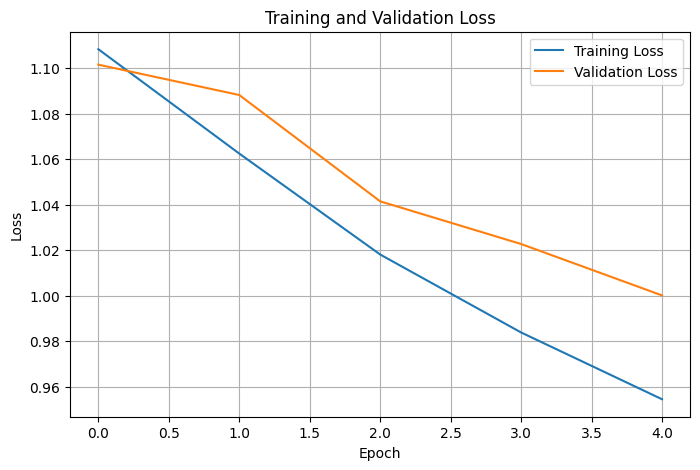

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

7.Plot Validation Metrics

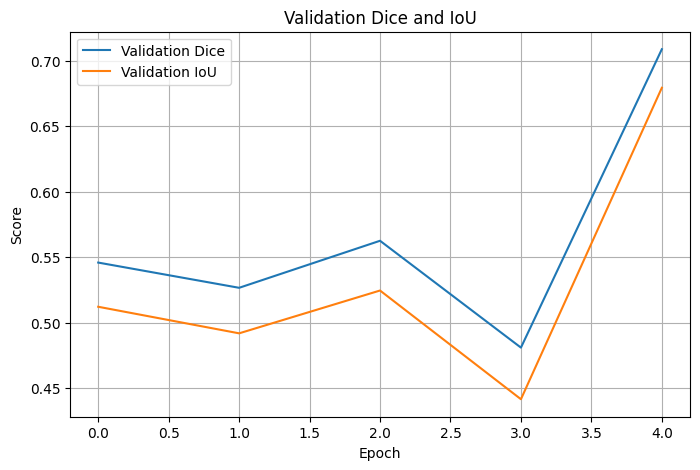

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history["val_dice"], label="Validation Dice")
plt.plot(history["val_iou"], label="Validation IoU")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Dice and IoU")
plt.legend()
plt.grid(True)

plt.show()

Q09:
Q09:
The training and validation losses decrease at every epoch (train: 1.1083 → 0.9545, validation: 1.1015 → 1.0001), which shows that the model is gradually learning. The validation Dice and IoU are less stable: they dip slightly at epoch 2 (Dice 0.5460 → 0.5267), recover at epoch 3 (0.5626), drop markedly at epoch 4 (0.4811, IoU 0.4417), then rise considerably at epoch 5 (Dice 0.7089, IoU 0.6794).

These fluctuations show that the validation loss and the Dice do not always move together, and that the Dice is sensitive to the many empty slices (65% of the masks are empty). Improvement therefore cannot be guaranteed with only five epochs: longer training and further evaluation are required to assess the model's effectiveness and its ability to generalize.

**A6.Visualize and Interpret Predictions**

In [ ]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Best checkpoint loaded successfully ")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["val_loss"])

Best checkpoint loaded successfully 
Best epoch: 5
Best validation loss: 1.0001141452789306


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random

def visualize_predictions(model, dataset, device, num_samples=3, threshold=0.5):

    model.eval()

    indices = random.sample(
        range(len(dataset)),
        min(num_samples, len(dataset))
    )

    for index in indices:

        image, ground_truth = dataset[index]

        image_input = image.unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(image_input)
            probabilities = torch.sigmoid(logits)

        probabilities = probabilities.squeeze().cpu().numpy()

        predicted_mask = (probabilities >= threshold).astype(np.float32)

        ground_truth = ground_truth.squeeze().numpy()

        intersection = np.sum(predicted_mask * ground_truth)
        union = np.sum((predicted_mask + ground_truth) > 0)

        dice = (2 * intersection + 1e-7) / (
            predicted_mask.sum() + ground_truth.sum() + 1e-7
        )

        iou = (intersection + 1e-7) / (union + 1e-7)

        mri_image = image[0].numpy()

        fig, axes = plt.subplots(1, 5, figsize=(20, 4))

        axes[0].imshow(mri_image, cmap="gray")
        axes[0].set_title("MRI Image")

        axes[1].imshow(ground_truth, cmap="gray")
        axes[1].set_title("Ground Truth")

        axes[2].imshow(probabilities, cmap="viridis", vmin=0, vmax=1)
        axes[2].set_title("Predicted Probabilities")

        axes[3].imshow(predicted_mask, cmap="gray")
        axes[3].set_title("Predicted Mask")

        axes[4].imshow(mri_image, cmap="gray")

        if ground_truth.max() > 0:
            axes[4].contour(
                ground_truth,
                levels=[0.5],
                colors="lime",
                linewidths=1.5
            )

        if predicted_mask.max() > 0:
            axes[4].contour(
                predicted_mask,
                levels=[0.5],
                colors="red",
                linewidths=1.5
            )

        axes[4].set_title("Overlay (GT: Green, Pred: Red)")

        for ax in axes:
            ax.axis("off")

        plt.suptitle(
            f"Sample {index} | Dice: {dice:.4f} | IoU: {iou:.4f}"
        )

        plt.tight_layout()
        plt.show()

        print(f"Sample {index} - Dice: {dice:.4f}, IoU: {iou:.4f}")

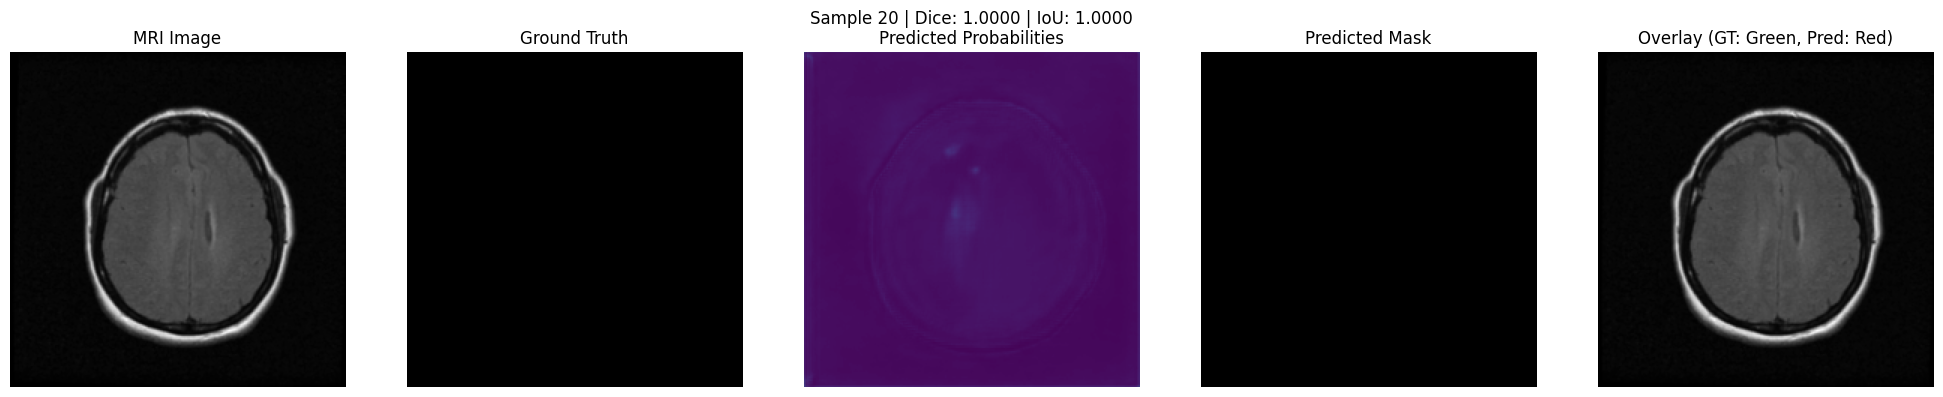

Sample 20 - Dice: 1.0000, IoU: 1.0000


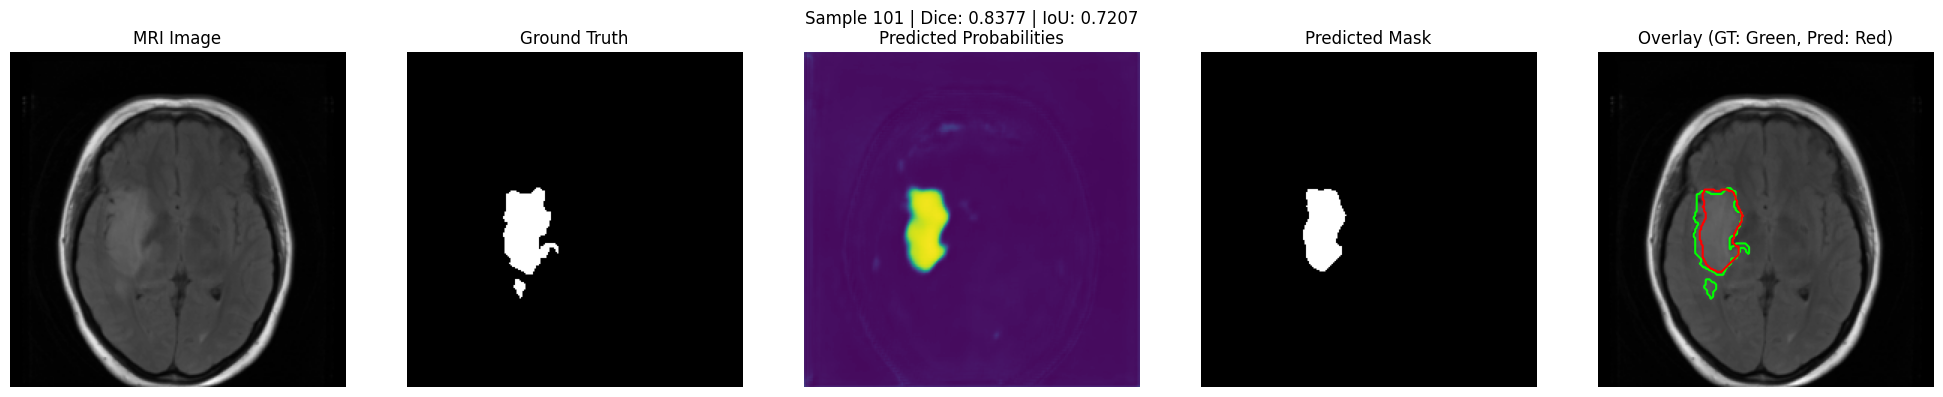

Sample 101 - Dice: 0.8377, IoU: 0.7207


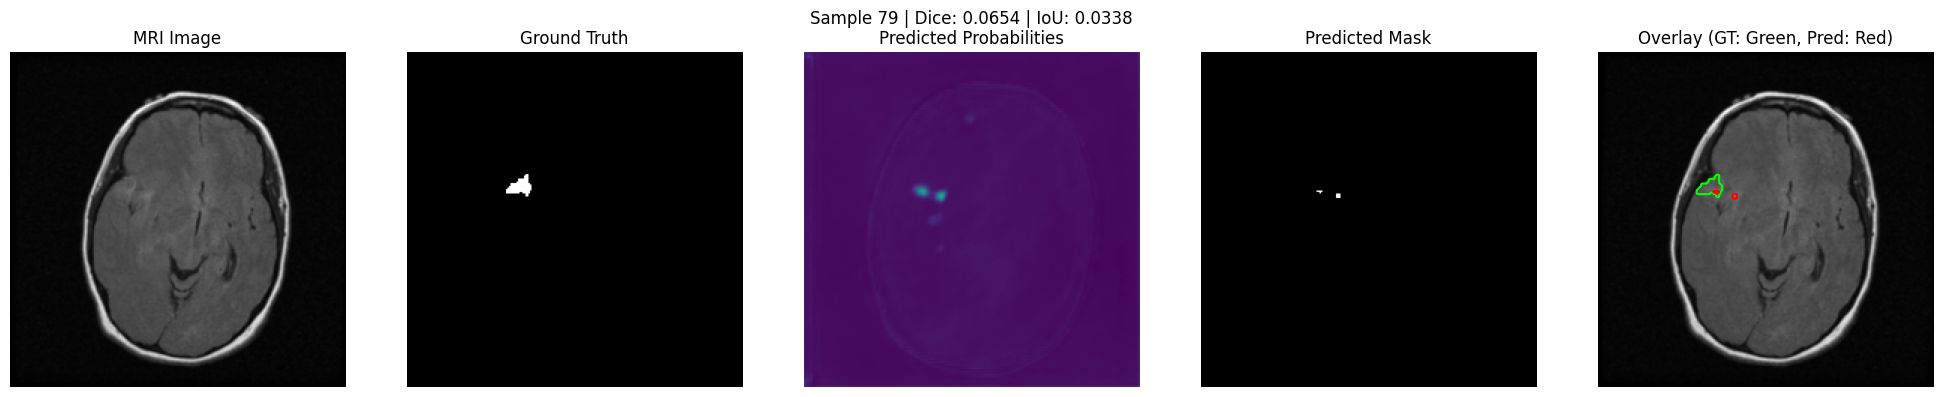

Sample 79 - Dice: 0.0654, IoU: 0.0338


In [ ]:
visualize_predictions(
    model=model,
    dataset=val_dataset,
    device=DEVICE,
    num_samples=3,
    threshold=0.5
)

In [ ]:
val_loss, val_dice, val_iou = validate_one_epoch(
    model,
    val_loader,
    DEVICE
)

validation_summary = {
    "best_epoch": checkpoint["epoch"],
    "best_val_loss": checkpoint["val_loss"],
    "val_dice": val_dice,
    "val_iou": val_iou
}

print("Validation Summary")
for metric, value in validation_summary.items():
    print(f"{metric}: {value:.4f}")

Validation Summary
best_epoch: 5.0000
best_val_loss: 1.0001
val_dice: 0.7089
val_iou: 0.6794


Q10:The predicted contours do not always perfectly match the annotated masks.Instances of false positives and false negatives are present, suggesting that the model might mistakenly detect or overlook specific areas of the tumor besides these inaccuracies underscore the challenges associated with the small size of the training dataset and the restricted amount of training epochs

# PART B : Freestyle Challenge

**Can Partial Fine-Tuning Improve Brain Tumor Segmentation?**
**bold text**

**B1.Restore the baseline model**

In [ ]:
import copy
from pathlib import Path

assert len(train_subset) == 1000 and len(val_subset) == 200 and len(test_subset) == 200
assert Path(BEST_MODEL_PATH).exists(), (
    "Baseline checkpoint not found: /content is erased when the Colab runtime is reset"
    "Re-run Part A (A0 -> A5) first"
)

checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

print("Baseline checkpoint restored")
print("Baseline epoch:", checkpoint["epoch"])
print("Baseline validation loss:", round(checkpoint["val_loss"], 4))

Baseline checkpoint restored
Baseline epoch: 5
Baseline validation loss: 1.0001


In [ ]:
@torch.no_grad()
def evaluate_per_image(model, loader, device, threshold=0.5, smooth=1.0):
    model.eval()
    dices, ious, has_tumor = [], [], []

    for images, masks in loader:
        images = images.to(device)
        masks = (masks.to(device) > 0).float()

        probs = torch.sigmoid(model(images))
        preds = (probs >= threshold).float()

        p = preds.view(preds.size(0), -1)
        t = masks.view(masks.size(0), -1)

        inter = (p * t).sum(dim=1)
        total = p.sum(dim=1) + t.sum(dim=1)
        union = total - inter

        dices.append(((2.0 * inter + smooth) / (total + smooth)).cpu())
        ious.append(((inter + smooth) / (union + smooth)).cpu())
        has_tumor.append((t.sum(dim=1) > 0).cpu())

    return (torch.cat(dices).numpy(),
            torch.cat(ious).numpy(),
            torch.cat(has_tumor).numpy())


def summarize(dice, iou, has_tumor):
    return {
        "dice": float(dice.mean()),
        "iou": float(iou.mean()),
        "dice_tumor": float(dice[has_tumor].mean()),
        "iou_tumor": float(iou[has_tumor].mean()),
    }

In [ ]:
base_dice, base_iou, has_tumor = evaluate_per_image(model, val_loader, DEVICE)
base_res = summarize(base_dice, base_iou, has_tumor)
base_val_loss, _, _ = validate_one_epoch(model, val_loader, DEVICE)

print("Baseline  | val loss :", round(base_val_loss, 4))
print("Baseline  | Dice     :", round(base_res["dice"], 4), "(Part A:", round(validation_summary["val_dice"], 4), ")")
print("Baseline  | IoU      :", round(base_res["iou"], 4), "(Part A:", round(validation_summary["val_iou"], 4), ")")
print("Baseline  | Dice on images with a tumor:", round(base_res["dice_tumor"], 4))
print(f"Validation images with a tumor: {has_tumor.sum()} / {len(has_tumor)}")

assert abs(base_res["dice"] - validation_summary["val_dice"]) < 5e-3, "Validation subset differs from Part A!"

baseline_model = copy.deepcopy(model).eval()

Baseline  | val loss : 1.0001
Baseline  | Dice     : 0.7089 (Part A: 0.7089 )
Baseline  | IoU      : 0.6794 (Part A: 0.6794 )
Baseline  | Dice on images with a tumor: 0.3851
Validation images with a tumor: 66 / 200


**B2. Change the trainable layers**

In [ ]:
#freeze the whole encoder
for param in model.encoder.parameters():
    param.requires_grad_(False)

#unfreeze only layer4
for param in model.encoder.layer4.parameters():
    param.requires_grad_(True)

#decoder and segmentation head stay trainable
for param in model.decoder.parameters():
    param.requires_grad_(True)
for param in model.segmentation_head.parameters():
    param.requires_grad_(True)

def count(params):
    return sum(p.numel() for p in params)

print("Encoder   total     :", count(model.encoder.parameters()))
print("  layer4  trainable :", count(p for p in model.encoder.layer4.parameters() if p.requires_grad))
print("  other encoder layers trainable:",
      count(p for n, p in model.encoder.named_parameters()
            if p.requires_grad and not n.startswith("layer4")))
print("Decoder   trainable :", count(p for p in model.decoder.parameters() if p.requires_grad))
print("Seg. head trainable :", count(p for p in model.segmentation_head.parameters() if p.requires_grad))
print("Trainable (model)   :", count(p for p in model.parameters() if p.requires_grad),
      "/", count(model.parameters()))

assert all(n.startswith("layer4") for n, p in model.encoder.named_parameters() if p.requires_grad)
assert all(p.requires_grad for p in model.encoder.layer4.parameters())

Encoder   total     : 21284672
  layer4  trainable : 13114368
  other encoder layers trainable: 0
Decoder   trainable : 3151552
Seg. head trainable : 145
Trainable (model)   : 16266065 / 24436369


**B3. New optimizer with two parameter groups**


In [ ]:
layer4_params = list(model.encoder.layer4.parameters())
decoder_head_params = (list(model.decoder.parameters())
                       + list(model.segmentation_head.parameters()))

optimizer_ft = torch.optim.AdamW([
    {"params": layer4_params,       "lr": 1e-5},
    {"params": decoder_head_params, "lr": 1e-4},
])

opt_ids = {id(p) for g in optimizer_ft.param_groups for p in g["params"]}
trainable_ids = {id(p) for p in model.parameters() if p.requires_grad}
assert opt_ids == trainable_ids

for i, g in enumerate(optimizer_ft.param_groups):
    print(f"Group {i}: lr = {g['lr']}, tensors = {len(g['params'])}, parameters = {count(g['params'])}")

Group 0: lr = 1e-05, tensors = 21, parameters = 13114368
Group 1: lr = 0.0001, tensors = 32, parameters = 3151697


**B4. Partial fine-tuning**


In [ ]:
FT_EPOCHS = 3
FT_MODEL_PATH = "/content/best_unet_partial_ft.pth"

torch.manual_seed(SEED)          # same shuffling seed as the start of Part A

best_ft_val_loss = float("inf")
history_ft = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": []}

print(f"Reference: baseline validation loss = {base_val_loss:.4f}")

for epoch in range(FT_EPOCHS):

    train_loss = train_one_epoch(model, train_loader, optimizer_ft, DEVICE)
    val_loss, val_dice, val_iou = validate_one_epoch(model, val_loader, DEVICE)

    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_dice"].append(val_dice)
    history_ft["val_iou"].append(val_iou)

    print(f"\nEpoch [{epoch + 1}/{FT_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")
    print(f"Validation IoU: {val_iou:.4f}")

    if val_loss < best_ft_val_loss:
        best_ft_val_loss = val_loss
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer_ft.state_dict(),
            "val_loss": val_loss,
        }, FT_MODEL_PATH)
        print("Best fine-tuning checkpoint saved.")

Reference: baseline validation loss = 1.0001

Epoch [1/3]
Train Loss: 0.9206
Validation Loss: 0.9708
Validation Dice: 0.5651
Validation IoU: 0.5316
Best fine-tuning checkpoint saved.

Epoch [2/3]
Train Loss: 0.8886
Validation Loss: 0.9609
Validation Dice: 0.6142
Validation IoU: 0.5795
Best fine-tuning checkpoint saved.

Epoch [3/3]
Train Loss: 0.8522
Validation Loss: 0.9414
Validation Dice: 0.6682
Validation IoU: 0.6333
Best fine-tuning checkpoint saved.


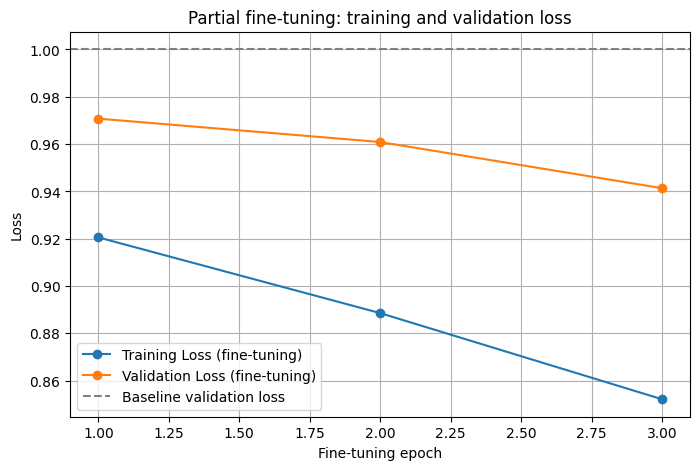

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, FT_EPOCHS + 1), history_ft["train_loss"], marker="o", label="Training Loss (fine-tuning)")
plt.plot(range(1, FT_EPOCHS + 1), history_ft["val_loss"], marker="o", label="Validation Loss (fine-tuning)")
plt.axhline(base_val_loss, color="gray", linestyle="--", label="Baseline validation loss")
plt.xlabel("Fine-tuning epoch")
plt.ylabel("Loss")
plt.title("Partial fine-tuning: training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

**B5. Fair comparison on the validation set**


In [ ]:
ft_ckpt = torch.load(FT_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(ft_ckpt["model_state_dict"])
model.to(DEVICE).eval()
print("Best fine-tuning epoch:", ft_ckpt["epoch"], "| val loss:", round(ft_ckpt["val_loss"], 4))

ft_dice, ft_iou, ft_has_tumor = evaluate_per_image(model, val_loader, DEVICE)
assert (ft_has_tumor == has_tumor).all()
ft_res = summarize(ft_dice, ft_iou, ft_has_tumor)

import pandas as pd
comparison = pd.DataFrame({
    "Indicateur (validation)": ["Dice Score", "IoU", "Dice sur images contenant une anomalie"],
    "Baseline : encoder frozen": [base_res["dice"], base_res["iou"], base_res["dice_tumor"]],
    "Partial Fine-Tuning":       [ft_res["dice"],  ft_res["iou"],  ft_res["dice_tumor"]],
}).set_index("Indicateur (validation)")
comparison["Difference"] = comparison["Partial Fine-Tuning"] - comparison["Baseline : encoder frozen"]

display(comparison.round(4))
print(f"\nValidation loss: baseline {base_val_loss:.4f} -> fine-tuning {ft_ckpt['val_loss']:.4f}")

Best fine-tuning epoch: 3 | val loss: 0.9414


,Baseline : encoder frozen,Partial Fine-Tuning,Difference
Indicateur (validation),,,
Dice Score,0.7089,0.6682,-0.0406
IoU,0.6794,0.6333,-0.0461
Dice sur images contenant une anomalie,0.3851,0.4508,0.0657



Validation loss: baseline 1.0001 -> fine-tuning 0.9414


In [ ]:
with torch.no_grad():
    def false_positive_images(m):
        count_fp = 0
        for images, masks in val_loader:
            preds = (torch.sigmoid(m(images.to(DEVICE))) >= 0.5).float()
            empty = (masks.view(masks.size(0), -1).sum(dim=1) == 0).to(DEVICE)
            predicted_something = preds.view(preds.size(0), -1).sum(dim=1) > 0
            count_fp += int((empty & predicted_something).sum())
        return count_fp

    n_empty = int((~has_tumor).sum())
    print(f"Empty validation images where a tumor is predicted (false alarms): "
          f"baseline {false_positive_images(baseline_model)}/{n_empty}  |  "
          f"fine-tuned {false_positive_images(model)}/{n_empty}")

Empty validation images where a tumor is predicted (false alarms): baseline 19/134  |  fine-tuned 31/134


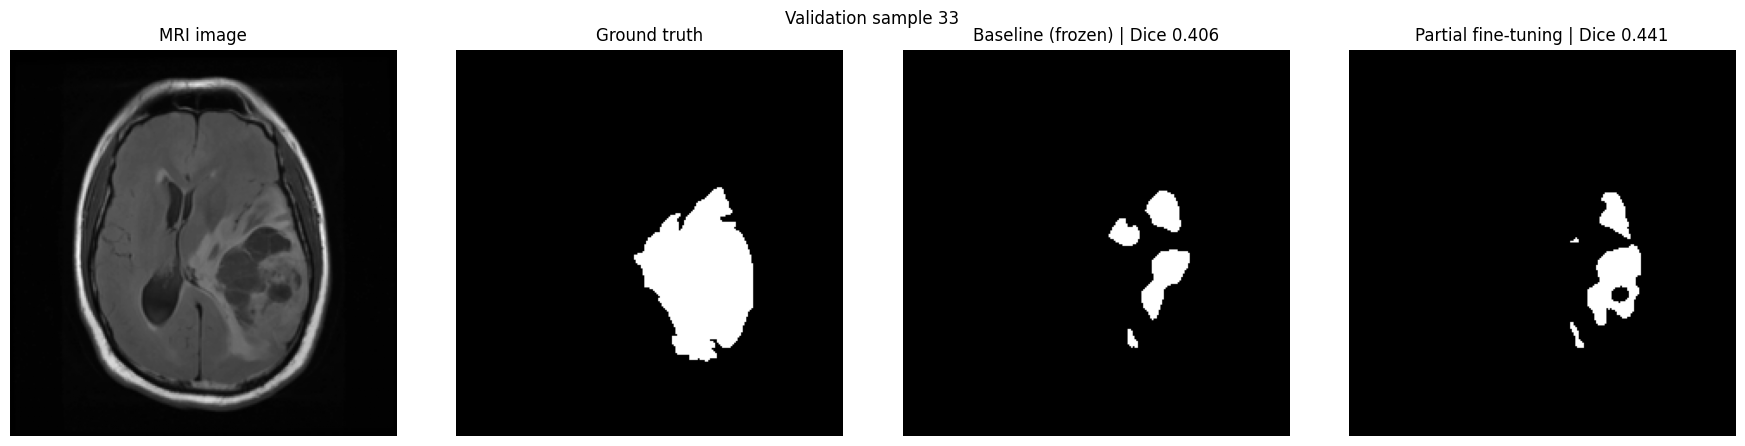

In [ ]:
rng = random.Random(SEED)
VIS_INDEX = rng.choice(np.where(has_tumor)[0].tolist())

image, gt = val_dataset[VIS_INDEX]
x = image.unsqueeze(0).to(DEVICE)

with torch.no_grad():
    base_mask = (torch.sigmoid(baseline_model(x)) >= 0.5).float().squeeze().cpu().numpy()
    ft_mask   = (torch.sigmoid(model(x)) >= 0.5).float().squeeze().cpu().numpy()

mri = image[0].numpy()
gt_np = gt.squeeze().numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(mri, cmap="gray");      axes[0].set_title("MRI image")
axes[1].imshow(gt_np, cmap="gray");    axes[1].set_title("Ground truth")
axes[2].imshow(base_mask, cmap="gray")
axes[2].set_title(f"Baseline (frozen) | Dice {base_dice[VIS_INDEX]:.3f}")
axes[3].imshow(ft_mask, cmap="gray")
axes[3].set_title(f"Partial fine-tuning | Dice {ft_dice[VIS_INDEX]:.3f}")
for ax in axes:
    ax.axis("off")
plt.suptitle(f"Validation sample {VIS_INDEX}")
plt.tight_layout()
plt.show()

Q01:The unfrozen layers are encoder.layer4, the decoder, and the segmentation head. The first layers (conv1, layer1 to layer3) retain generic features learned from ImageNet. Since layer4 contains more specialized features, fine-tuning it helps adapt the model to MRI images while limiting overfitting with a small dataset

Q02:layer4 is already pretrained, so a high learning rate could modify its weights too much and destabilize training also the decoder and segmentation head are specific to the segmentation task so they can learn faster with a learning rate of 1e-4

Q03:Partial fine-tuning enhanced the segmentation for images with tumors: the Dice score for these images rose from 0.3851 to 0.4508 an increase of 0.0657 while the validation loss dropped from 1.0001 to 0.9414 with the best performance noted at epoch 3. Nevertheless, the overall Dice score fell from 0.7089 to 0.6682 a decline of 0.0406 and the IoU also decreased from 0.6794 to 0.6333 which is a reduction of 0.0461


Visual observation:The tumor itself constitutes a significant, dense area. Both of the models fail to accurately segment it: their output masks are divided into tiny patches and only encompass a portion of the tumor leading to numerous false negative results. The adjusted model shows a marginally superior performance (Dice: 0.441 compared to 0.406). Its predicted mask encompasses a marginally greater area yet it is still lacking and has a void within the identified section. This aligns with the slight enhancement in Dice scores observed in images that feature tumors